In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**TP 1 - Pedretti Jose Ignacio**

Dataset de registros académicos que contiene información sobre alumnos que continúan, abandonan o se gradúan, junto con variables académicas, laborales y económicas

## Carga de datos

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/DiploIA/TP1/academic_survival_longitudinal.csv")

In [ ]:
df

,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored
0,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,1,...,0.0,2.85,85.8,67.0,0,0,1.7,0,Enrolled,0
1,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,2,...,0.0,2.73,81.0,89.0,1,0,3.1,0,Enrolled,0
2,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,3,...,0.0,2.60,78.3,60.0,0,2,3.0,0,Enrolled,0
3,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,4,...,0.0,2.34,77.2,59.0,2,3,5.1,0,Enrolled,0
4,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,5,...,0.0,1.90,79.3,53.0,1,2,3.6,0,Enrolled,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79234,STU_19998,19,Female,0,61000.0,2,Off-Campus,0,15000,2,...,0.0,3.16,86.6,81.0,2,1,1.0,0,Enrolled,1
79235,STU_19999,19,Female,1,70000.0,5,On-Campus,1,15000,1,...,0.0,2.73,85.5,55.0,1,0,1.6,0,Enrolled,0
79236,STU_19999,19,Female,1,70000.0,5,On-Campus,1,15000,2,...,0.0,2.76,80.1,59.0,0,0,1.7,1,Dropped_Out,0
79237,STU_20000,21,Female,0,113000.0,1,With Parents,0,15000,1,...,2251.0,3.51,93.4,71.0,0,1,1.0,0,Enrolled,0


In [ ]:
df.shape

(79239, 22)

In [ ]:
df.head()

,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored
0,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,1,...,0.0,2.85,85.8,67.0,0,0,1.7,0,Enrolled,0
1,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,2,...,0.0,2.73,81.0,89.0,1,0,3.1,0,Enrolled,0
2,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,3,...,0.0,2.60,78.3,60.0,0,2,3.0,0,Enrolled,0
3,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,4,...,0.0,2.34,77.2,59.0,2,3,5.1,0,Enrolled,0
4,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,5,...,0.0,1.90,79.3,53.0,1,2,3.6,0,Enrolled,1


In [ ]:
df.info() ## no todos tienen datos de Family_Income y LMS_Logins

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79239 entries, 0 to 79238
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Student_ID               79239 non-null  object 
 1   Age                      79239 non-null  int64  
 2   Gender                   79239 non-null  object 
 3   First_Generation         79239 non-null  int64  
 4   Family_Income            75635 non-null  float64
 5   Household_Size           79239 non-null  int64  
 6   Housing_Status           79239 non-null  object 
 7   Scholarship              79239 non-null  int64  
 8   Tuition_Base             79239 non-null  int64  
 9   Semester                 79239 non-null  int64  
 10  Course_Load              79239 non-null  int64  
 11  Work_Hours               79239 non-null  float64
 12  Emergency_Expense        79239 non-null  float64
 13  Sem_GPA                  79239 non-null  float64
 14  Attendance            

In [ ]:
df.Course_Load.unique()

array([15, 18, 12,  9, 21])

In [ ]:
df.isnull().sum()

,0
Student_ID,0
Age,0
Gender,0
First_Generation,0
Family_Income,3604
Household_Size,0
Housing_Status,0
Scholarship,0
Tuition_Base,0
Semester,0


In [ ]:
df.shape

(79239, 22)

In [ ]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'First_Generation', 'Family_Income',
       'Household_Size', 'Housing_Status', 'Scholarship', 'Tuition_Base',
       'Semester', 'Course_Load', 'Work_Hours', 'Emergency_Expense', 'Sem_GPA',
       'Attendance', 'LMS_Logins', 'Advising_Visits', 'Failed_Courses',
       'Financial_Stress', 'Target_Dropout_Next_Sem', 'End_of_Semester_Status',
       'Censored'],
      dtype='object')

In [ ]:
df.describe()


,Age,First_Generation,Family_Income,Household_Size,Scholarship,Tuition_Base,Semester,Course_Load,Work_Hours,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,Censored
count,79239.000000,79239.000000,75635.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,78372.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000
mean,19.492005,0.327894,61518.384346,3.187547,0.277515,24775.110741,3.145673,14.888615,16.936129,200.496788,2.691463,85.081599,66.375670,0.477530,0.652494,2.578287,0.087293,0.140272
std,2.139140,0.469449,39661.166570,1.332861,0.447775,10794.899387,1.946207,2.307308,10.724479,724.400513,0.422692,6.415864,12.730793,0.671954,0.786066,1.817880,0.282266,0.347271
min,17.000000,0.000000,3000.000000,1.000000,0.000000,15000.000000,1.000000,9.000000,0.000000,0.000000,0.440000,-2.000000,12.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,18.000000,0.000000,35000.000000,2.000000,0.000000,15000.000000,1.000000,12.000000,8.300000,0.000000,2.440000,81.200000,58.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,19.000000,0.000000,52000.000000,3.000000,0.000000,25000.000000,3.000000,15.000000,16.500000,0.000000,2.700000,85.200000,66.000000,0.000000,0.000000,2.100000,0.000000,0.000000
75%,21.000000,1.000000,77000.000000,4.000000,1.000000,25000.000000,4.000000,15.000000,24.900000,0.000000,2.960000,89.200000,75.000000,1.000000,1.000000,3.400000,0.000000,0.000000
max,37.000000,1.000000,488000.000000,6.000000,1.000000,45000.000000,8.000000,21.000000,40.000000,3998.000000,3.960000,105.000000,116.000000,3.000000,5.000000,18.600000,1.000000,1.000000


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.End_of_Semester_Status.unique()

array(['Enrolled', 'Dropped_Out', 'Graduated'], dtype=object)

In [ ]:
datos = df["End_of_Semester_Status"].value_counts()

In [ ]:
df["End_of_Semester_Status"].value_counts()

,count
End_of_Semester_Status,
Enrolled,70354
Dropped_Out,6917
Graduated,1968


Distribución por estado al cierre del semestre

**Objetivo:** encontrar insigts relevantes para determinar factores de abandono estudiantil.

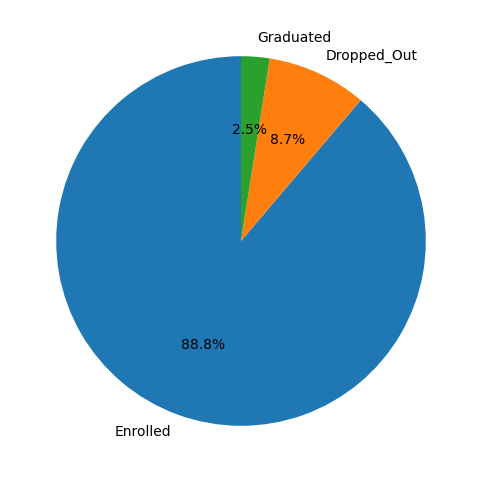

In [ ]:
plt.figure(figsize=(8,6))
datos = df.End_of_Semester_Status.value_counts()
plt.pie(datos, labels=datos.index, autopct='%1.1f%%', startangle=90)
plt.show()

**Aanalizar q viariables academicas, laborales, contexto, tienen relacion con el abandono.**

1. Qué relación existe entre las horas de trabajo y el abandono estudiantil?
2. Los estudiantes con menor rendimiento académico presentan mayores porcentajes de abandono?
3. Qué relación tienen la asistencia y los accesos al campus virtual con el abandono?
4. Cómo cambia la tasa de abandono según el semestre y la cantidad de materias cursadas?
5. Qué relación existe entre el estrés financiero, las horas de trabajo y el abandono?

## inconsistencias: Attendance: ver candidad de datos por fuera del 0 al 100 %

In [ ]:
df[df["Attendance"] < 0]["Attendance"].value_counts()

,count
Attendance,
-2.0,85


In [ ]:
df[df["Attendance"] > 100]["Attendance"].value_counts()

,count
Attendance,
101.0,84
105.0,80


#Inconsistencias en attendance, hay 85 datos por debajo del 0% y 164 (249) por encima del 100 % (79239 casos)
#LMS_Logins y Family_Income hay datos faltantes

In [ ]:
df["Family_Income"] = df["Family_Income"].fillna(df["Family_Income"].median()) ### Reemplazamos los valores nulos de family income por la mediana.

**Reemplacé valores inconsistentes por la mediana para que no afecte el promedio**

In [ ]:
df.loc[(df["Attendance"] < 0) | (df["Attendance"] > 100), "Attendance"] = np.nan

In [ ]:
df["Attendance"].isnull().sum()

np.int64(249)

In [ ]:
porcentaje = (249 / 79239) * 100
print(porcentaje)

0.3142392003937455


In [ ]:
df["Attendance"] = df["Attendance"].fillna(df["Attendance"].median())

In [ ]:
df["Attendance"].isnull().sum()

np.int64(0)

In [ ]:
df["Attendance"].min(), df["Attendance"].max()

(58.7, 100.0)

In [ ]:
df.Attendance.describe()

,Attendance
count,79239.000000
mean,85.138399
std,5.688261
min,58.700000
25%,81.200000
50%,85.200000
75%,89.100000
max,100.000000


# **Attendance** > 249 valores inconsistentes (0,31% del dataset), correspondientes a valores menores a 0% y superiores a 100%. Se reemplazaron por valores nulos y se imputaron utilizando la mediana de la variable.

#**Valores atípicos**: Family_Income

In [ ]:
Q1 = df["Family_Income"].quantile(0.25)
Q3 = df["Family_Income"].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR
outliers = df[
    (df["Family_Income"] < limite_inferior) |
    (df["Family_Income"] > limite_superior)]
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)
print("Cantidad de valores atípicos:", len(outliers))
print("Porcentaje:", round(len(outliers) / len(df) * 100, 2))


Límite inferior: -25000.0
Límite superior: 135000.0
Cantidad de valores atípicos: 4002
Porcentaje: 5.05


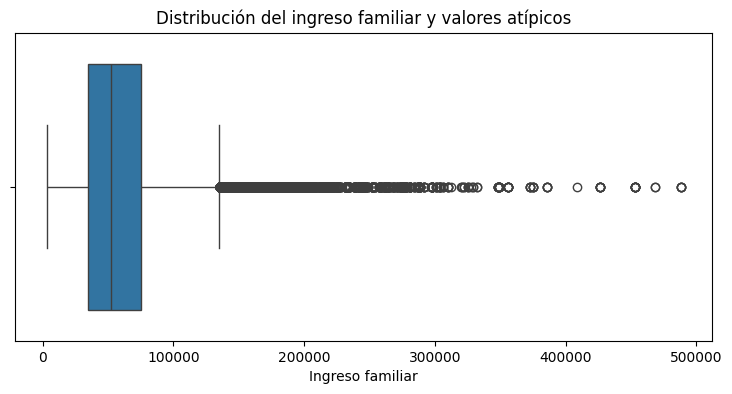

In [ ]:
plt.figure(figsize=(9, 4))

sns.boxplot(data=df, x="Family_Income")

plt.xlabel("Ingreso familiar")
plt.title("Distribución del ingreso familiar y valores atípicos")
plt.show()

### Identificación y tratamiento de valores atípicos

Se analizaron los posibles valores atípicos de la variable **Family_Income** mediante el método del rango IQR.

El análisis estableció un límite inferior de -25.000 y un límite superior de 135.000, identificando 4.002 registros fuera de estos límites, equivalentes al 5,05% del total de observaciones.

El límite inferior negativo responde al cálculo estadístico del método y no implica necesariamente la existencia de ingresos familiares negativos.

A diferencia de los valores inconsistentes detectados en la variable **Attendance**, los ingresos familiares elevados no necesariamente representan errores de registro, ya que podrían corresponder a situaciones económicas reales.

Por este motivo, se decidió conservar los valores atípicos identificados, evitando eliminar observaciones que podrían aportar información relevante sobre la diversidad de situaciones económicas de los estudiantes.

In [ ]:
print("Ingresos negativos:", (df["Family_Income"] < 0).sum())

Ingresos negativos: 0


No hay ingresos negativos

### Variables utilizadas

En el dataset encontramos dos variables relacionadas con el abandono estudiantil, pero cada una muestra información diferente:

- **End_of_Semester_Status:** indica la situación del estudiante al finalizar el semestre: si continúa cursando, abandonó o se graduó.
- **Target_Dropout_Next_Sem:** indica si el estudiante abandona en el semestre siguiente. El valor 0 significa que no abandona y el 1 que sí abandona.

Para este análisis utilizamos principalmente **Target_Dropout_Next_Sem**, porque nos permite comparar las características de los estudiantes que abandonan con las de quienes continúan.

**End_of_Semester_Status** la utilizamos solamente para conocer la distribución de los estudiantes según su situación académica al finalizar el semestre.

# **Horas de trabajo y abandono**



Boxplot1

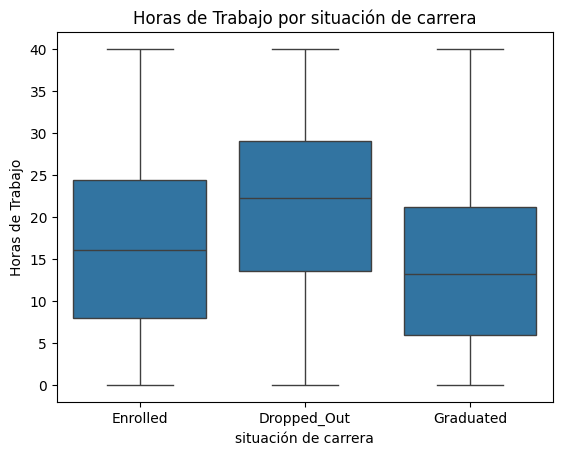

In [ ]:
sns.boxplot(data=df, x='End_of_Semester_Status', y='Work_Hours')
plt.title('Horas de Trabajo por situación de carrera')
plt.xlabel('situación de carrera')
plt.ylabel('Horas de Trabajo')
plt.show()

In [ ]:
df.groupby("Target_Dropout_Next_Sem")["Work_Hours"].mean()

,Work_Hours
Target_Dropout_Next_Sem,
0,16.519759
1,21.289562


**Horas de trabajo según futuro abandono**

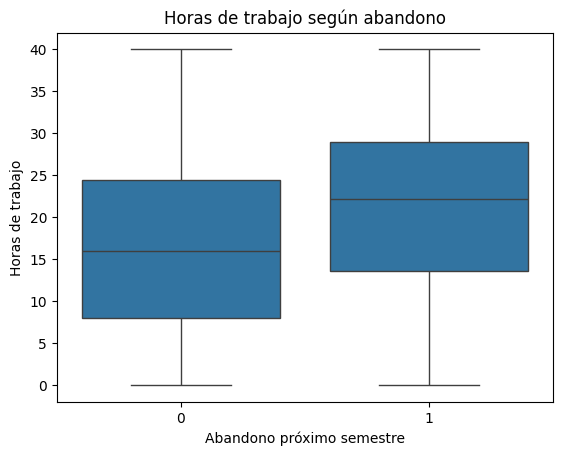

In [ ]:
sns.boxplot(data=df, x="Target_Dropout_Next_Sem", y="Work_Hours")
plt.xlabel("Abandono próximo semestre")
plt.ylabel("Horas de trabajo")
plt.title("Horas de trabajo según abandono")
plt.show()

Los estudiantes que abandonan trabajan más horas en promedio

**Distribución de las horas de trabajo**

Cómo se distribuyen las horas de trabajo de los estudiantes, antes de comparar a quienes abandonan con quienes no.

Text(0.5, 1.0, 'Distribucion de hrs de trabajo')

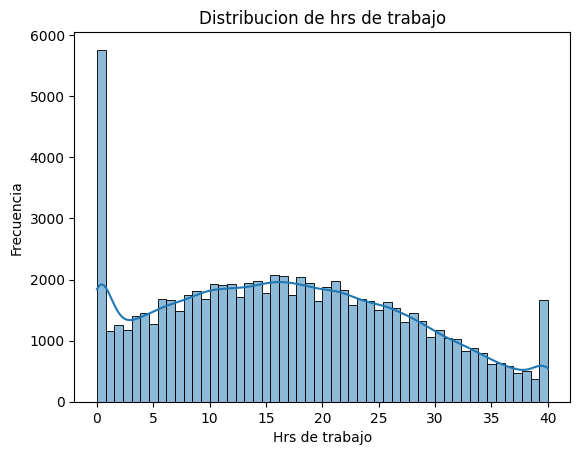

In [ ]:
sns.histplot(data=df, x="Work_Hours", kde=True)
plt.xlabel("Hrs de trabajo")
plt.ylabel("Cantidad de registros")
plt.title("Distribucion de hrs de trabajo")

Concentración en 0 horas y una mayor cantidad de registros de valores medios, entre 10 y 22 horas semanales. suba en 40 hrs.

Los alumnos presentan distintas cargas laborales. El gráfico describe la carga laboral general, pero no demuestra por sí mismo una asociación con el abandono.

In [ ]:
df.groupby("Target_Dropout_Next_Sem")["Work_Hours"].mean()

,Work_Hours
Target_Dropout_Next_Sem,
0,16.519759
1,21.289562


In [ ]:
df.groupby("Target_Dropout_Next_Sem")["Work_Hours"].median()

,Work_Hours
Target_Dropout_Next_Sem,
0,16.0
1,22.2


##**Conclusión**: Los alumnos que abandonan trabajan en promedio 21,29 horas, frente a 16,52 horas de quienes continúan.

Evaluar acompañamiento académico para alumnos con mayor carga laboral.

In [ ]:
pd.crosstab([df.Advising_Visits], [df.Target_Dropout_Next_Sem], normalize="index") * 100

Target_Dropout_Next_Sem,0,1
Advising_Visits,,
0,92.645368,7.354632
1,89.841628,10.158372
2,86.382114,13.617886
3,85.714286,14.285714


**Boxplot2**
# **Distribución de los accesos al campus online**
 ---



In [ ]:
df["LMS_Logins"] = df["LMS_Logins"].fillna(df["LMS_Logins"].median())

In [ ]:
df.groupby("Target_Dropout_Next_Sem")["LMS_Logins"].mean()

,LMS_Logins
Target_Dropout_Next_Sem,
0,66.708097
1,62.852826


Reemplazamos los valores nulos de lms_logins por la mediana, los resultados no cambian mucho, por lo que la conclución no cambia.


**Previo a reemplazar valores nulos: LMS_Logins**
##Target_Dropout_Next_Sem
#0 	66.715987
#1 	62.820651
**Después del Reemplazo: LMS_Logins**
##Target_Dropout_Next_Sem
#0 	66.708097
#1 	62.852826

Más actividad en el campus, mayor vinculacion adacemica ?

Text(0.5, 1.0, 'Acceso al campus online')

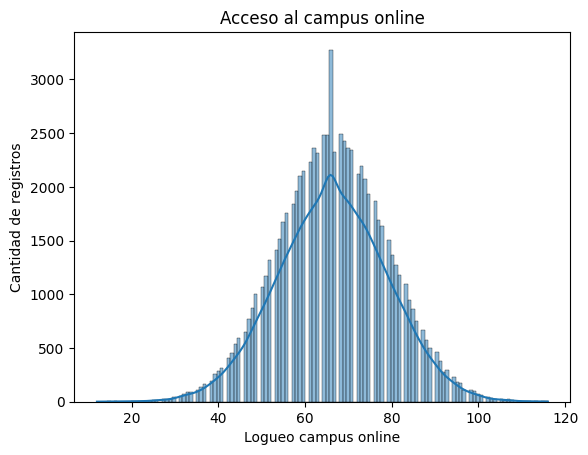

In [164]:
sns.histplot(data=df, x="LMS_Logins", kde=True)
plt.xlabel("Logueo campus online")
plt.ylabel("Cantidad de registros")
plt.title("Acceso al campus online")

Accesos al campus online según abandono

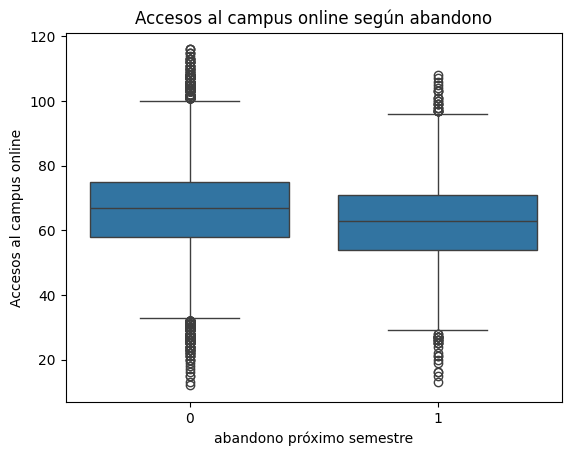

In [ ]:
sns.boxplot(data=df, x="Target_Dropout_Next_Sem", y="LMS_Logins")
plt.xlabel("abandono próximo semestre")
plt.ylabel("Accesos al campus online")
plt.title("Accesos al campus online según abandono")
plt.show()

**Conclución:** Los alumnos que abandonan en el próximo semestre presentan una menor cantidad de accesos al campus online (62,85 en promedio) en comparación con aquellos que continúan (66,71). La cantidad de accesos al campus virtual no presenta diferencias marcadas entre los que abandonaron y los que no, no necesariamente son un indicadores de riesgo de abandono por si solos.
Puede utilizarse como señal de posible abandono y dar mayor acompañamiento de manera preventiva.

---



# Distribución del promedio académico

Boxplot3
# **Promedio del semestre Vs abandono**

cómo rinden los estudiantes en general

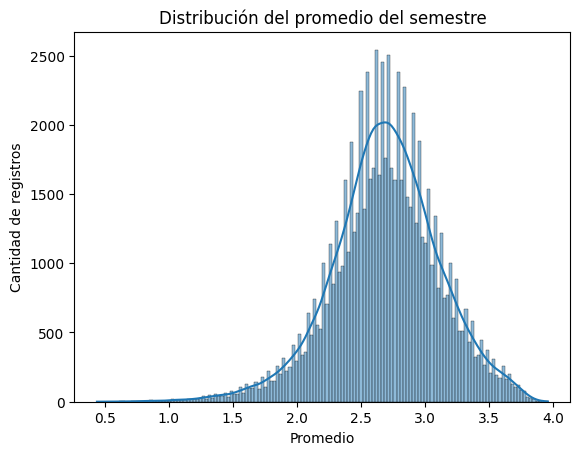

In [163]:
sns.histplot(data=df, x="Sem_GPA", kde=True)
plt.xlabel("Promedio")
plt.ylabel("Cantidad de registros")
plt.title("Distribución del promedio del semestre")
plt.show()

Rendimiento general: Concentración de estudiantes en valores intermedios, entre 2,5 y 3,0, con una menor frecuencia de promedios extremos.


La Cantidad de registros disminuye hacia ambos extremos, por lo que hay menos alumnos con promedios muy bajos o cercanos a 4.

In [ ]:
df.groupby("Target_Dropout_Next_Sem")["Sem_GPA"].median()

,Sem_GPA
Target_Dropout_Next_Sem,
0,2.72
1,2.40


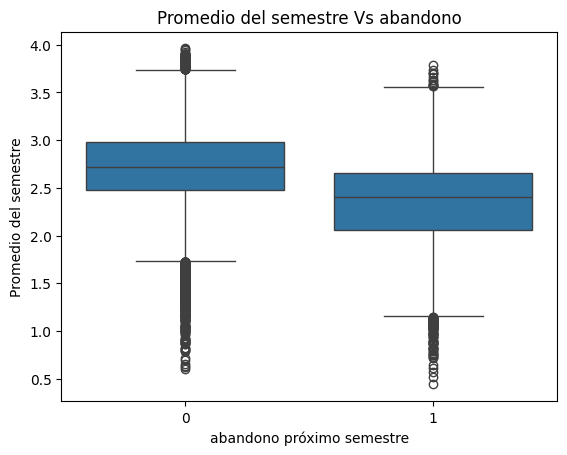

In [ ]:
sns.boxplot(data=df, x="Target_Dropout_Next_Sem", y="Sem_GPA")
plt.xlabel("abandono próximo semestre")
plt.ylabel("Promedio del semestre")
plt.title("Promedio del semestre Vs abandono")
plt.show()

quienes abandonan tienden a tener promedios más bajos

## **Conclusión:**
Los alumnos que abandonan presentan un rendimiento académico menor, con medianas de 2,40 y 2,72. Bajo rendimiento académico, mayor riesgo de abandono.
---





# **Menos asistencias mas abandono?**

In [ ]:
df.groupby("Target_Dropout_Next_Sem")["Attendance"].mean()

,Attendance
Target_Dropout_Next_Sem,
0,85.317621
1,83.264508


**Target_Dropout_Next_Sem Vs Course_Load**

In [ ]:
tasa_abandono_carga = (df.groupby("Course_Load")["Target_Dropout_Next_Sem"].mean().mul(100).reset_index(name="Tasa_abandono"))

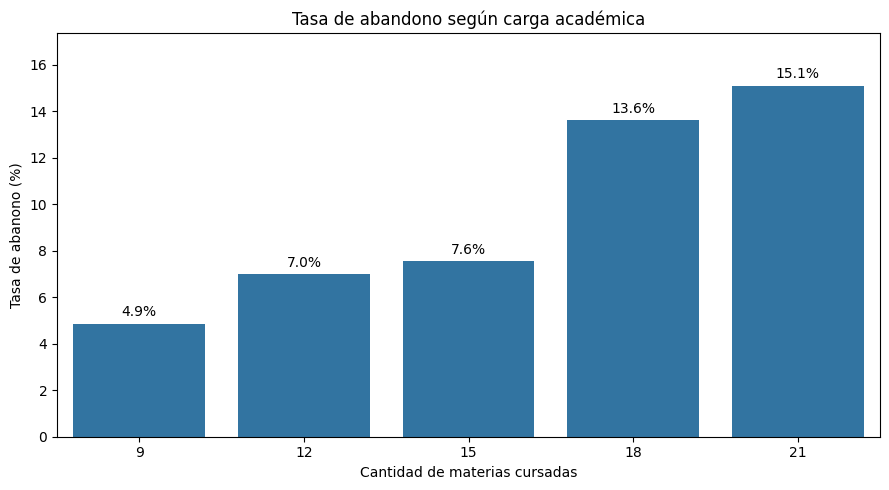

In [ ]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=tasa_abandono_carga,
                 x="Course_Load",
                 y="Tasa_abandono")
plt.xlabel("Cantidad de materias cursadas")
plt.ylabel("Tasa de abanono (%)")
plt.title("Tasa de abandono según carga académica")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)
plt.ylim(0, tasa_abandono_carga["Tasa_abandono"].max() * 1.15)
plt.tight_layout()
plt.show()


In [ ]:
display(tasa_abandono_carga.round(2))

,Course_Load,Tasa_abandono
0,9,4.87
1,12,6.98
2,15,7.55
3,18,13.63
4,21,15.11


El abandono aumenta a medida que se cursan más materias.

**Hs de trabajo Vs. promedio académico**

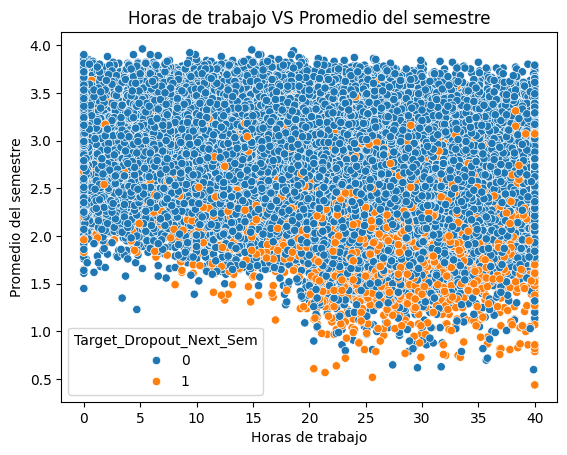

In [ ]:
sns.scatterplot(data=df, x="Work_Hours", y="Sem_GPA",hue="Target_Dropout_Next_Sem")
plt.xlabel("Horas de trabajo")
plt.ylabel("Promedio del semestre")
plt.title("Horas de trabajo VS Promedio del semestre")
plt.show()

muchas horas de trabajo + bajo GPA
muchas horas de trabajo + GPA alto
pocas horas de trabajo + bajo GPA
pocas horas de trabajo + GPA alto


Calcular la tasa de abancono de cada grupo.

In [ ]:
## Medianas generales de horas trabajadas y promedio académico.

In [ ]:
print("Mediana de horas de trabajo:", df["Work_Hours"].median())
print("Mediana del GPA:", df["Sem_GPA"].median())

Mediana de horas de trabajo: 16.5
Mediana del GPA: 2.7


los puntos de corte de 16,5 horas y 2,7 de GPA correspondan a las medianas

In [ ]:
df["Carga_Laboral"] = np.where(df["Work_Hours"] > 16.5, "Muchas horas","Pocas horas")
df["Rendimiento"] = np.where( df["Sem_GPA"] >= 2.7, "GPA alto","GPA bajo")

In [ ]:
df["Grupo"] = df["Carga_Laboral"] + " + " + df["Rendimiento"]

In [ ]:
df["Grupo"].value_counts()

,count
Grupo,
Pocas horas + GPA alto,23392
Muchas horas + GPA bajo,22919
Muchas horas + GPA alto,16506
Pocas horas + GPA bajo,16422


In [ ]:
df.groupby("Grupo")["Target_Dropout_Next_Sem"].mean() * 100

,Target_Dropout_Next_Sem
Grupo,
Muchas horas + GPA alto,4.731613
Muchas horas + GPA bajo,17.068808
Pocas horas + GPA alto,3.283174
Pocas horas + GPA bajo,8.866155


**Relación entre la carga laboral, rendimiento académico y abanodno:** Se clasificó a los estudiantes en 4 grupos. Carga laboral alta cuando las horas de trabajo superan las 16,5 semanales, y un rendimiento académico alto cuando el GPA es igual o superior a 2,7.

In [ ]:
tasa_grupo = df.groupby("Grupo")["Target_Dropout_Next_Sem"].mean() * 100

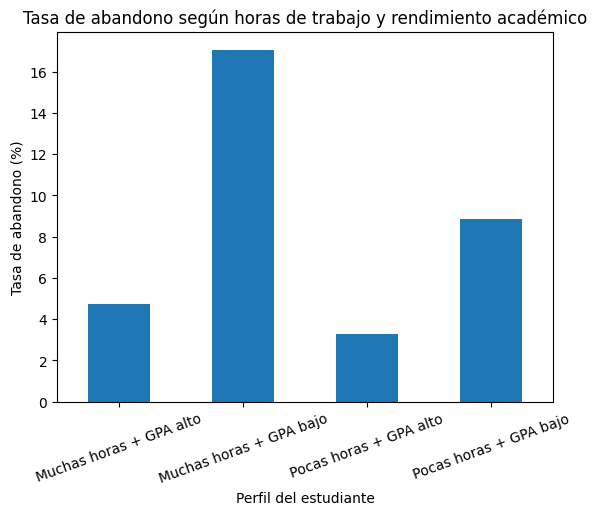

In [ ]:
tasa_grupo.plot(kind="bar")
plt.xlabel("Perfil del estudiante")
plt.ylabel("Tasa de abandono (%)")
plt.title("Tasa de abandono según horas de trabajo y rendimiento académico")
plt.xticks(rotation=20)
plt.show()

Alunnos con mayor carga laboral y menor rendimiento académico presentan la tasa de abandono más elevada (17,07%). Aquellos con menor carga laboral y mejor rendimiento tienen la más baja (3,28%).

La combinación de exigencia laboral y dificultades académicas podría estar asociada con un mayor indice de abandono.

In [ ]:
df.groupby("Grupo")["Target_Dropout_Next_Sem"].mean() * 100

,Target_Dropout_Next_Sem
Grupo,
Muchas horas + GPA alto,4.731613
Muchas horas + GPA bajo,17.068808
Pocas horas + GPA alto,3.283174
Pocas horas + GPA bajo,8.866155


**La asistencia cambia según vivienda?**

In [ ]:
df["Housing_Status"].value_counts()

,count
Housing_Status,
On-Campus,31315
With Parents,24767
Off-Campus,23157


In [ ]:
df.groupby("Housing_Status")["Attendance"].mean()

,Attendance
Housing_Status,
Off-Campus,85.242644
On-Campus,85.189941
With Parents,84.975762


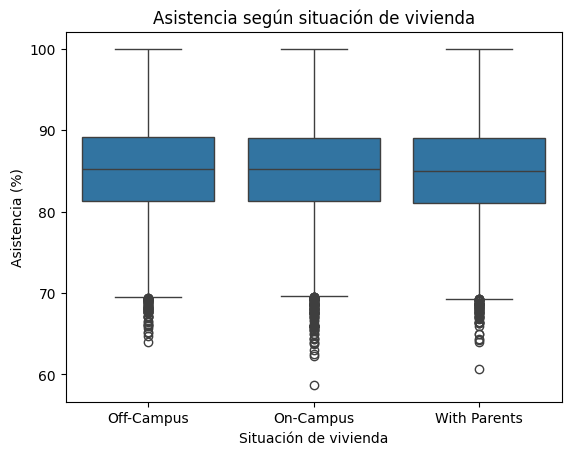

In [ ]:
sns.boxplot(data=df, x="Housing_Status", y="Attendance")
plt.xlabel("Situación de vivienda")
plt.ylabel("Asistencia (%)")
plt.title("Asistencia según situación de vivienda")
plt.show()

**No aparece una diferencia descriptiva importante.**\

---



# Asistencia promedio según abandono

In [ ]:
attendance_abandono = df.groupby("Target_Dropout_Next_Sem")["Attendance"].mean()

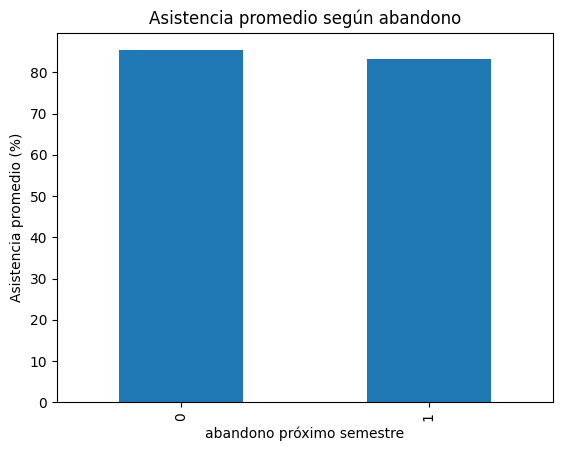

In [ ]:
attendance_abandono.plot(kind="bar")
plt.xlabel("abandono próximo semestre")
plt.ylabel("Asistencia promedio (%)")
plt.title("Asistencia promedio según abandono")
plt.show()

**Conclución:** Los alumnos que abandonan presentan 83,26% de asistencia promedio, frente a 85,32% de quienes continúan.
la diferencia es relativamente baja.

---



# Tasa de abandono según semestre

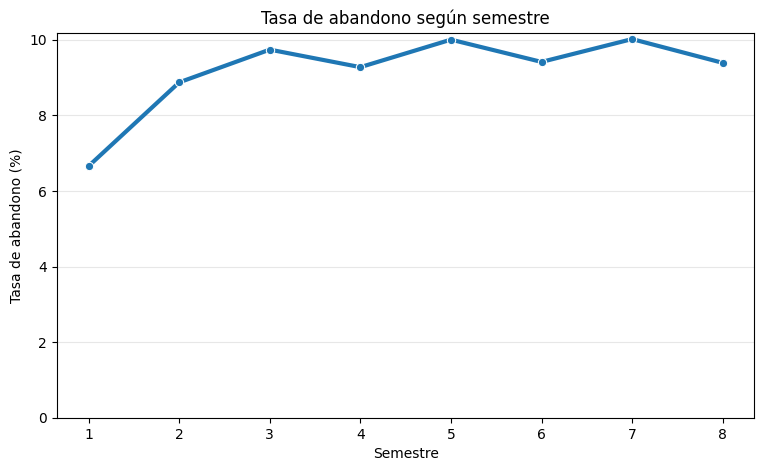

In [ ]:
tasa_abandono = df.groupby("Semester")["Target_Dropout_Next_Sem"].mean() * 100
plt.figure(figsize=(9, 5))
sns.lineplot(x=tasa_abandono.index,y=tasa_abandono.values, marker="o",linewidth=3)
plt.xlabel("Semestre")
plt.ylabel("Tasa de abandono (%)")
plt.title("Tasa de abandono según semestre")
plt.xticks(tasa_abandono.index)
plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

**Conclusión:** La tasa de abandono aumenta desde aproximadamente el 6,7% en el primer semestre hasta valores cercanos al 10% en los semestres posteriores. A partir del tercer semestre, se mantiene relativamente estable.

Esto muestra que el abandono no ocurre solamente al inicio de la carrera, sino también en etapas más avanzadas. Por eso, sería importante mantener el seguimiento de los alumnos durante toda su trayectoria académica.

In [ ]:
##Desaprobados Vs Abandono

In [ ]:
df.groupby("Target_Dropout_Next_Sem")["Failed_Courses"].mean()

,Failed_Courses
Target_Dropout_Next_Sem,
0,0.599970
1,1.201677


**estrés financiero y abandono**

In [ ]:
df.groupby("Target_Dropout_Next_Sem")["Financial_Stress"].mean()

,Financial_Stress
Target_Dropout_Next_Sem,
0,2.454519
1,3.872372


In [ ]:
### Ver cuales son los factores que mas influyen en el abandono > buscar un insight relevante que no se vea a simple vista

In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
Student_ID,0
Age,0
Gender,0
First_Generation,0
Family_Income,0
Household_Size,0
Housing_Status,0
Scholarship,0
Tuition_Base,0
Semester,0


In [ ]:
df.describe()


,Age,First_Generation,Family_Income,Household_Size,Scholarship,Tuition_Base,Semester,Course_Load,Work_Hours,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,Censored
count,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000
mean,19.492005,0.327894,61085.462966,3.187547,0.277515,24775.110741,3.145673,14.888615,16.936129,200.496788,2.691463,85.138399,66.371559,0.477530,0.652494,2.578287,0.087293,0.140272
std,2.139140,0.469449,38799.432822,1.332861,0.447775,10794.899387,1.946207,2.307308,10.724479,724.400513,0.422692,5.688261,12.661013,0.671954,0.786066,1.817880,0.282266,0.347271
min,17.000000,0.000000,3000.000000,1.000000,0.000000,15000.000000,1.000000,9.000000,0.000000,0.000000,0.440000,58.700000,12.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,18.000000,0.000000,35000.000000,2.000000,0.000000,15000.000000,1.000000,12.000000,8.300000,0.000000,2.440000,81.200000,58.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,19.000000,0.000000,52000.000000,3.000000,0.000000,25000.000000,3.000000,15.000000,16.500000,0.000000,2.700000,85.200000,66.000000,0.000000,0.000000,2.100000,0.000000,0.000000
75%,21.000000,1.000000,75000.000000,4.000000,1.000000,25000.000000,4.000000,15.000000,24.900000,0.000000,2.960000,89.100000,75.000000,1.000000,1.000000,3.400000,0.000000,0.000000
max,37.000000,1.000000,488000.000000,6.000000,1.000000,45000.000000,8.000000,21.000000,40.000000,3998.000000,3.960000,100.000000,116.000000,3.000000,5.000000,18.600000,1.000000,1.000000


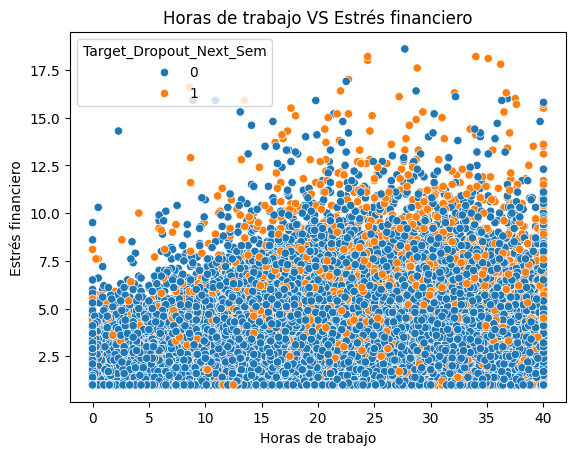

In [ ]:
sns.scatterplot(data=df, x="Work_Hours", y="Financial_Stress", hue="Target_Dropout_Next_Sem")
plt.xlabel("Horas de trabajo")
plt.ylabel("Estrés financiero")
plt.title("Horas de trabajo VS Estrés financiero")
plt.show()

Los grupos se construyen utilizando las medianas generales de ambas variables.

In [ ]:
df["Carga_Laboral"] = np.where(df["Work_Hours"] > df["Work_Hours"].median(), "Muchas horas", "Pocas horas")
df["Nivel_Estres"] = np.where(df["Financial_Stress"] > df["Financial_Stress"].median(), "Alto estrés","Bajo estrés")
df["Grupo_Estres_Trabajo"] = (df["Nivel_Estres"] + " + " + df["Carga_Laboral"])
df.groupby("Grupo_Estres_Trabajo")["Target_Dropout_Next_Sem"].mean() * 100

,Target_Dropout_Next_Sem
Grupo_Estres_Trabajo,
Alto estrés + Muchas horas,14.968863
Alto estrés + Pocas horas,8.809755
Bajo estrés + Muchas horas,5.957796
Bajo estrés + Pocas horas,4.130514


### Insight — Estrés financiero y carga laboral ###

Para analizar la relación entre el estrés financiero, la carga laboral y el abandono, se clasificó a los estudiantes en cuatro grupos utilizando las medianas generales de ambas variables.

In [ ]:
tasa_grupo = df.groupby("Grupo_Estres_Trabajo")["Target_Dropout_Next_Sem"].mean() * 100

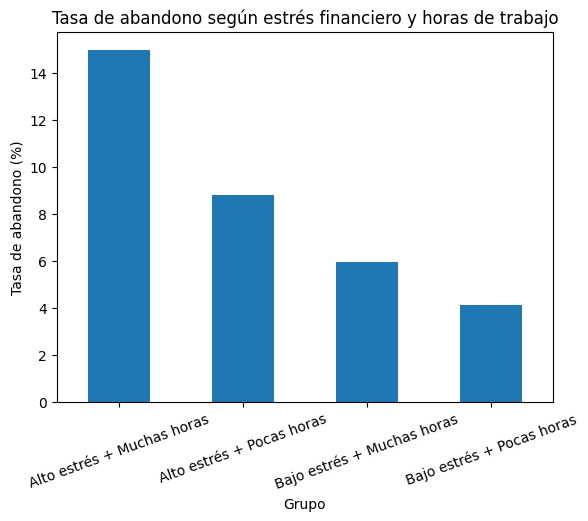

In [ ]:
tasa_grupo.plot(kind="bar")
plt.xlabel("Grupo")
plt.ylabel("Tasa de abandono (%)")
plt.title("Tasa de abandono según estrés financiero y horas de trabajo")
plt.xticks(rotation=20)
plt.show()

Los alumnos con alto estrés financiero y muchas horas de trabajo presentan la tasa de abandono más alta (14,97%), mientras que aquellos con bajo estrés financiero y pocas horas de trabajo registran la más baja (4,13%).

Esta diferencia muestra que la combinación de presión económica y muchas horas de trabajo podría estar relacionada con un mayor abandono estudiantil.

**Cantidad de registros por grupo**

In [162]:
resumen = df.groupby("Grupo_Estres_Trabajo").agg(Registros=("Target_Dropout_Next_Sem", "size"),Registros_con_abandono=("Target_Dropout_Next_Sem", "sum"),
    Tasa_Abandono=("Target_Dropout_Next_Sem", "mean"))
resumen["Tasa_Abandono"] = (
    resumen["Tasa_Abandono"] * 100).round(2)
display(resumen)


,Registros,Registros_con_abandono,Tasa_Abandono
Grupo_Estres_Trabajo,,,
Alto estrés + Muchas horas,26014,3894,14.97
Alto estrés + Pocas horas,12384,1091,8.81
Bajo estrés + Muchas horas,13411,799,5.96
Bajo estrés + Pocas horas,27430,1133,4.13


In [ ]:
df[["Financial_Stress", "Sem_GPA"]].median()

,0
Financial_Stress,2.1
Sem_GPA,2.7


In [ ]:
## Family_Income ## Financial_Stress

In [ ]:
df[["Family_Income", "Financial_Stress", "Age"]].median()

,0
Family_Income,52000.0
Financial_Stress,2.1
Age,19.0


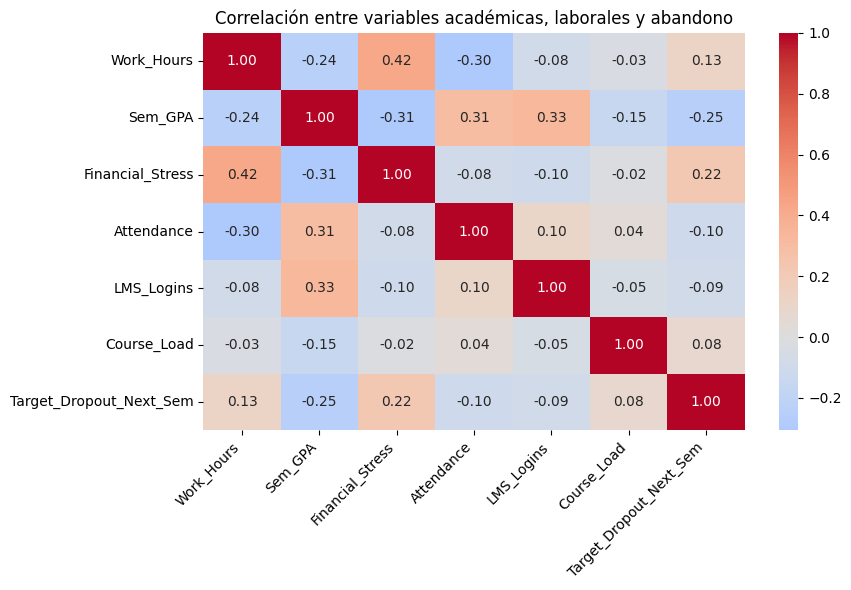

In [ ]:
variables = ["Work_Hours","Sem_GPA","Financial_Stress","Attendance","LMS_Logins","Course_Load","Target_Dropout_Next_Sem"]
correlaciones = df[variables].corr()
plt.figure(figsize=(9, 6))
sns.heatmap(correlaciones,annot=True,cmap="coolwarm",fmt=".2f", center=0)
plt.title("Correlación entre variables académicas, laborales y abandono")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Conclusión:** El rendimiento académico (-0,25) y el estrés financiero (0,22) son las variables que presentan mayor correlación con el abandono estudiantil entre las analizadas, aunque los valores no son muy altos.

También encontramos que los estudiantes que trabajan más horas tienden a tener menor asistencia (-0,30).

Estos resultados muestran que el abandono podría estar relacionado con distintos factores académicos, laborales y económicos, aunque no podemos afirmar que sean sus causas.

### Principales hallazgos e insights de negocio

## 1. Rendimiento académico

Los estudiantes que abandonan tienen un GPA más bajo que los que continúan (medianas de 2,40 y 2,72).

Esto podría servir para identificar alumnos que necesitan mayor seguimiento y buscar formas de incentivar las visitas de asesoramiento académico **Advising_Visits.**

### 2. Horas de trabajo y rendimiento

Los estudiantes que abandonan trabajan en promedio 21,29 horas semanales, frente a 16,52 de los que continúan.

Al combinar trabajo y rendimiento, el abandono llega al **17,07%** entre quienes trabajan muchas horas y tienen un GPA bajo, frente al **3,28%** de quienes trabajan menos y tienen mejor rendimiento.

Se podrían evaluar alternativas de cursada más flexibles o asincrónicas para acompañar a estos estudiantes.

### 3. Estrés financiero y trabajo

Los estudiantes con mayor estrés financiero y más horas de trabajo presentan un **14,97% de abandono**, frente al **4,13%** de quienes tienen menor estrés y trabajan menos.

Esto podría ayudar a identificar alumnos que necesitan apoyo económico y evaluar mayores oportunidades de acceso a becas y beneficios.

### 4. Asistencia y campus virtual

Los estudiantes que abandonan tienen menos accesos al campus virtual (62,85 frente a 66,71) y una asistencia algo menor (83,26% frente a 85,32%).

Ambas variables podrían servir como señales para hacer un seguimiento de los alumnos, aunque por sí solas no indican que vayan a abandonar.

### 5. Abandono según el semestre

El abandono es menor en el primer semestre (6,7%), aumenta en los siguientes y después se mantiene cerca del 9% y 10%.

Esto muestra que el seguimiento de los alumnos no debería concentrarse solamente en los ingresantes, sino también en quienes están más avanzados en la carrera.

---
Durante el análisis también revise otras variables, como la situación de vivienda, pero no encotré diferencias importantes en la asistencia según esta variable. Por eso decidi concentrarnos en los resultados que consideré más relevantes para analizar el abandono estudiantil.

Esto no significa que las variables que dejamos de lado no tengan relación con el abandono, sino que no profundizamos en ellas dentro de este trabajo.

---
## Conclusión general

El análisis permitió encontrar relaciones entre el abandono y factores como el rendimiento académico, las horas de trabajo, el estrés financiero y la participación académica.

Uno de los principales resultados es que **los alumnos que trabajan muchas horas y tienen bajo rendimiento presentan mayores porcentajes de abandono**. Algo similar ocurre cuando se combinan muchas horas de trabajo y estrés financiero elevado.

Estos resultados podrían ayudar a la universidad a identificar perfiles que necesitan mayor acompañamiento y pensar acciones para mejorar la permanencia de los alumnos.

De todas formas, se trata de un análisis exploratorio, por lo que podemos identificar relaciones entre variables, pero no asegurar que sean las causas del abandono.